# ML-08 — Capstone Modeling Lane

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Method choice and why

*Which method from the toolkit, and why it fits your lane.*

Task: the label is yes or no (is a page declining), and I rank pages by predicted probability of decline, so this is classification used for ranking.

Methods compared: my Week 4 baseline rule, logistic regression, a decision tree, a random forest, and gradient boosting. I started with logistic regression because it is simple and easy to explain, then added the tree and the ensembles to test whether extra complexity earns anything. My choice is logistic regression as the reference model, because it ties gradient boosting on ROC AUC (0.610 vs 0.611) and has the best grouped 5-fold mean (0.662). The ranked queue in my capstone comes from gradient boosting, which was equal on the main split.

## 2. Split design

*Grouped by client? Time-aware? Say why this split is honest for your question.*

Client-grouped holdout: 25 clients (23,837 pages) in training and 7 clients (6,163 pages) in testing, with zero clients in both. Pages from the same client share patterns, so a random split would be too easy. The baseline and every model are scored on this same test set. I also ran a grouped 5-fold check. The starter file has no dates, so a time-aware split has to wait for the warehouse data.

## 3. Train + compare vs my baseline

*Same data, same metric, same split as your Week-4 baseline. Show the table.*

In [1]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv("../../data/raw/content_refresh_anonymized.csv")
y = (df['trend_direction'] == 'down').astype(int)

X = pd.DataFrame({
    'log_impressions': np.log1p(df['impressions_90d']),
    'log_clicks': np.log1p(df['clicks_90d']),
    'avg_position': df['avg_position'],
    'log_word_count': np.log1p(df['word_count'].fillna(0)),
    'log_days_since_update': np.log1p(df['days_since_last_update']),
})
X = pd.concat([X, pd.get_dummies(df['content_type'], prefix='type').astype(int)], axis=1)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=df['client_id']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train pages:", len(X_train), "| Test pages:", len(X_test))
print("Train clients:", df.iloc[train_idx]['client_id'].nunique(), "| Test clients:", df.iloc[test_idx]['client_id'].nunique())
print("Clients in both:", len(set(df.iloc[train_idx]['client_id']) & set(df.iloc[test_idx]['client_id'])))
print("Declining share, train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train pages: 23837 | Test pages: 6163
Train clients: 25 | Test clients: 7
Clients in both: 0
Declining share, train: 0.55 | test: 0.511


In [2]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

def precision_at_k(y_true, score, k):
    top = np.argsort(-np.asarray(score))[:k]
    return float(np.asarray(y_true)[top].mean())

def evaluate(name, score):
    return {
        'method': name,
        'roc_auc': roc_auc_score(y_test, score),
        'avg_precision': average_precision_score(y_test, score),
        'precision_at_50': precision_at_k(y_test, score, 50),
        'precision_at_100': precision_at_k(y_test, score, 100),
    }

baseline_all = df['days_since_last_update'].rank(pct=True) * df['impressions_90d'].rank(pct=True)
baseline_test = baseline_all.iloc[test_idx].values

models = {
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'decision tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42),
    'random forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1),
    'gradient boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42),
}

rows = [evaluate('baseline rule (week 4)', baseline_test)]
scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    scores[name] = model.predict_proba(X_test)[:, 1]
    rows.append(evaluate(name, scores[name]))

results = pd.DataFrame(rows).round(3)
print("Test pages:", len(y_test), "| base rate (declining share):", round(float(y_test.mean()), 3))
print(results.to_string(index=False))

os.makedirs("../outputs", exist_ok=True)
results.to_json("../outputs/w05_results.json", orient="records", indent=2)

Test pages: 6163 | base rate (declining share): 0.511
                method  roc_auc  avg_precision  precision_at_50  precision_at_100
baseline rule (week 4)    0.475          0.472             0.34              0.32
   logistic regression    0.610          0.607             0.76              0.77
         decision tree    0.585          0.562             0.62              0.58
         random forest    0.592          0.577             0.68              0.63
     gradient boosting    0.611          0.600             0.74              0.73


On the same client-held-out split (6,163 test pages, base rate of declining pages 0.511), my Week 4 baseline scored a ROC AUC of 0.475 and precision@50 of 0.34. Logistic regression scored 0.610 and 0.76, and gradient boosting scored 0.611 and 0.74. The decision tree (0.585) and random forest (0.592) were lower on ROC AUC. Grouped 5-fold mean ROC AUC was 0.585 for the baseline, 0.662 for logistic regression, 0.628 for the tree, 0.653 for the forest and 0.633 for boosting. Every model beats the baseline, but the gain is modest, and the more complex models did not win just by being complex. Precision@50 should be read against the 0.511 base rate.

## 4. Errors and interpretation

*Where is the model wrong? What does it lean on? A short error analysis beats a big metric table.*

In [3]:
from sklearn.inspection import permutation_importance

best_name = results[results['method'] != 'baseline rule (week 4)'].sort_values('roc_auc', ascending=False).iloc[0]['method']
best_model = models[best_name]
print("Best by ROC AUC:", best_name)

perm = permutation_importance(best_model, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print(importance.head(8).round(4))

test_df = df.iloc[test_idx].copy()
test_df['prob'] = scores[best_name]
flagged = test_df['prob'] >= test_df['prob'].quantile(0.8)
actual = y_test.values == 1

test_df['outcome'] = np.select(
    [flagged & actual, flagged & ~actual, ~flagged & actual],
    ['caught (true positive)', 'false alarm (false positive)', 'missed (false negative)'],
    default='correctly left alone'
)

profile = test_df.groupby('outcome').agg(
    pages=('content_id', 'count'),
    median_impressions=('impressions_90d', 'median'),
    median_position=('avg_position', 'median'),
    median_days_since_update=('days_since_last_update', 'median'),
    median_word_count=('word_count', 'median'),
).round(1)
print(profile)

Best by ROC AUC: gradient boosting
log_impressions            0.0697
log_clicks                 0.0640
avg_position               0.0308
log_word_count             0.0026
type_comparison article    0.0000
type_feedly article        0.0000
type_keyword article       0.0000
log_days_since_update     -0.0128
dtype: float64
                              pages  median_impressions  median_position  \
outcome                                                                    
caught (true positive)          770               776.0              9.8   
correctly left alone           2548               265.0              9.9   
false alarm (false positive)    466              1155.5             15.4   
missed (false negative)        2379               309.0              9.0   

                              median_days_since_update  median_word_count  
outcome                                                                    
caught (true positive)                            20.0             27

Permutation importance (gradient boosting): log impressions 0.070, log clicks 0.064, average position 0.031, word count 0.003, days since update -0.013. This shows which signals the model used, not that any signal causes decline.

Flagging the top 20 percent of test pages by predicted risk caught 770 declining pages, produced 466 false alarms, and missed 2,379 declining pages. False alarms are high-visibility pages (median 1,156 impressions, median position 15.4). Missed pages have lower traffic (median 309 impressions). Median days since update was 20 for every group, so staleness does not separate them.

Caveat: the label compares the last 30 days with the previous 30, and my 90-day features cover the same days, so some of the skill may come from overlapping measurements. This is decision-support on a proxy label.

SPLIT
train pages: 23837 test pages: 6163
train clients: 25 test clients: 7
clients in both: 0
declining share train: 0.55 test: 0.511

RESULTS
                method  roc_auc  avg_precision  precision_at_50  precision_at_100
baseline rule (week 4)    0.475          0.472             0.34              0.32
   logistic regression    0.610          0.607             0.76              0.77
         decision tree    0.585          0.562             0.62              0.58
         random forest    0.592          0.577             0.68              0.63
     gradient boosting    0.611          0.600             0.74              0.73

GROUPED 5-FOLD ROC AUC
                        mean_auc  std_auc
baseline rule (week 4)     0.585    0.089
logistic regression        0.662    0.051
decision tree              0.628    0.038
random forest              0.653    0.038
gradient boosting          0.633    0.065

BEST MODEL: gradient boosting

PERMUTATION IMPORTANCE
log_impressions            0.0697

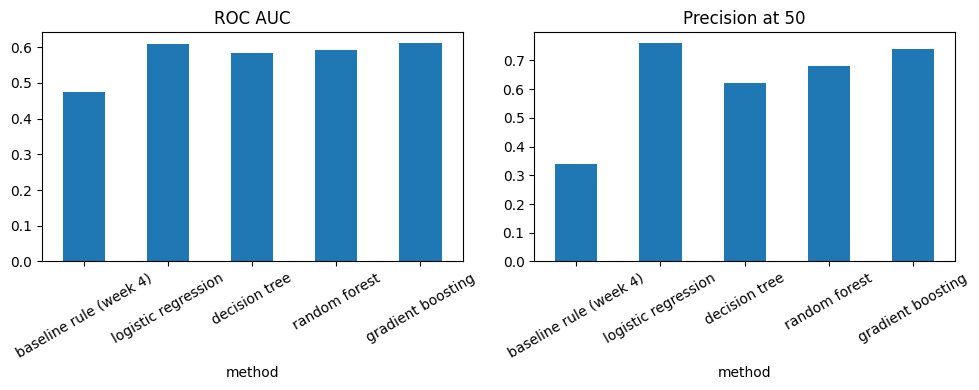

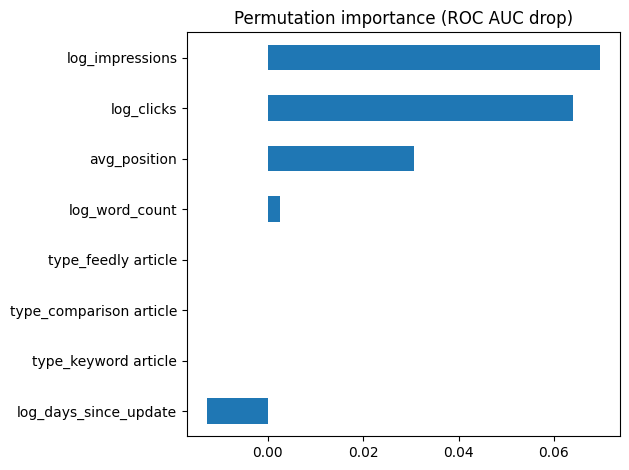

In [4]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

df = pd.read_csv("../../data/raw/content_refresh_anonymized.csv")
y = (df['trend_direction'] == 'down').astype(int)

X = pd.DataFrame({
    'log_impressions': np.log1p(df['impressions_90d']),
    'log_clicks': np.log1p(df['clicks_90d']),
    'avg_position': df['avg_position'],
    'log_word_count': np.log1p(df['word_count'].fillna(0)),
    'log_days_since_update': np.log1p(df['days_since_last_update']),
})
X = pd.concat([X, pd.get_dummies(df['content_type'], prefix='type').astype(int)], axis=1)

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups=df['client_id']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("SPLIT")
print("train pages:", len(X_train), "test pages:", len(X_test))
print("train clients:", df.iloc[train_idx]['client_id'].nunique(), "test clients:", df.iloc[test_idx]['client_id'].nunique())
print("clients in both:", len(set(df.iloc[train_idx]['client_id']) & set(df.iloc[test_idx]['client_id'])))
print("declining share train:", round(y_train.mean(), 3), "test:", round(y_test.mean(), 3))

def precision_at_k(y_true, score, k):
    top = np.argsort(-np.asarray(score))[:k]
    return float(np.asarray(y_true)[top].mean())

def evaluate(name, score):
    return {'method': name, 'roc_auc': roc_auc_score(y_test, score), 'avg_precision': average_precision_score(y_test, score),
            'precision_at_50': precision_at_k(y_test, score, 50), 'precision_at_100': precision_at_k(y_test, score, 100)}

baseline_all = df['days_since_last_update'].rank(pct=True) * df['impressions_90d'].rank(pct=True)
models = {
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'decision tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42),
    'random forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1),
    'gradient boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42),
}

rows = [evaluate('baseline rule (week 4)', baseline_all.iloc[test_idx].values)]
scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    scores[name] = model.predict_proba(X_test)[:, 1]
    rows.append(evaluate(name, scores[name]))
results = pd.DataFrame(rows).round(3)
print("\nRESULTS")
print(results.to_string(index=False))

cv = {'baseline rule (week 4)': []}
for name in models:
    cv[name] = []
for tr, te in GroupKFold(n_splits=5).split(X, y, groups=df['client_id']):
    cv['baseline rule (week 4)'].append(roc_auc_score(y.iloc[te], baseline_all.iloc[te]))
    for name, model in models.items():
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        cv[name].append(roc_auc_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1]))
cv_table = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in cv.items()}, index=['mean_auc', 'std_auc']).T.round(3)
print("\nGROUPED 5-FOLD ROC AUC")
print(cv_table)

best_name = results[results['method'] != 'baseline rule (week 4)'].sort_values('roc_auc', ascending=False).iloc[0]['method']
best_model = models[best_name]
print("\nBEST MODEL:", best_name)

perm = permutation_importance(best_model, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print("\nPERMUTATION IMPORTANCE")
print(importance.head(8).round(4))

test_df = df.iloc[test_idx].copy()
test_df['prob'] = scores[best_name]
flagged = test_df['prob'] >= test_df['prob'].quantile(0.8)
actual = y_test.values == 1
test_df['outcome'] = np.select([flagged & actual, flagged & ~actual, ~flagged & actual],
                               ['caught', 'false_alarm', 'missed'], default='correctly_left_alone')
profile = test_df.groupby('outcome').agg(pages=('content_id', 'count'), median_impressions=('impressions_90d', 'median'),
                                         median_position=('avg_position', 'median'),
                                         median_days_since_update=('days_since_last_update', 'median'),
                                         median_word_count=('word_count', 'median')).round(1)
print("\nERROR PROFILE (top 20 percent flagged)")
print(profile)

stale_visible = (test_df['days_since_last_update'] >= 180) & (test_df['impressions_90d'] >= 500)
test_df['reason_code'] = np.where(stale_visible, 'stale_visible_page',
                          np.where((test_df['impressions_90d'] >= 500) & flagged, 'visible_decline_risk', 'model_decline_risk'))
test_df['action'] = np.where(test_df['reason_code'] == 'stale_visible_page', 'refresh',
                     np.where(test_df['reason_code'] == 'visible_decline_risk', 'review', 'monitor'))
ranked = test_df.sort_values('prob', ascending=False).reset_index(drop=True)
ranked['rank'] = ranked.index + 1
print("\nTOP 20 QUEUE")
print(ranked[['rank', 'content_id', 'prob', 'impressions_90d', 'avg_position', 'days_since_last_update', 'reason_code', 'action']].head(20).round(3).to_string(index=False))
print("\nactual decline rate in top 20:", round(float(ranked.head(20)['trend_direction'].eq('down').mean()), 3))
print("reason code counts in top 100:")
print(ranked.head(100)['reason_code'].value_counts())

os.makedirs("../outputs", exist_ok=True)
results.to_json("../outputs/w05_results.json", orient="records", indent=2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
results.plot.bar(x='method', y='roc_auc', ax=axes[0], legend=False, rot=30, title='ROC AUC')
results.plot.bar(x='method', y='precision_at_50', ax=axes[1], legend=False, rot=30, title='Precision at 50')
plt.tight_layout()
plt.savefig("../outputs/model_vs_baseline.png", dpi=150)
plt.show()

importance.head(8).sort_values().plot.barh(title='Permutation importance (ROC AUC drop)')
plt.tight_layout()
plt.savefig("../outputs/feature_importance.png", dpi=150)
plt.show()

In [5]:
print(importance.head(8).round(4))
print()
print(profile)
print()
print(ranked[['rank', 'impressions_90d', 'avg_position', 'days_since_last_update', 'prob', 'reason_code', 'action']].head(20).round(3).to_string(index=False))
print()
print("actual decline rate in top 20:", round(float(ranked.head(20)['trend_direction'].eq('down').mean()), 3))
print("actual decline rate in top 100:", round(float(ranked.head(100)['trend_direction'].eq('down').mean()), 3))
print("test base rate:", round(float(y_test.mean()), 3))

log_impressions            0.0697
log_clicks                 0.0640
avg_position               0.0308
log_word_count             0.0026
type_comparison article    0.0000
type_feedly article        0.0000
type_keyword article       0.0000
log_days_since_update     -0.0128
dtype: float64

                      pages  median_impressions  median_position  \
outcome                                                            
caught                  770               776.0              9.8   
correctly_left_alone   2548               265.0              9.9   
false_alarm             466              1155.5             15.4   
missed                 2379               309.0              9.0   

                      median_days_since_update  median_word_count  
outcome                                                            
caught                                    20.0             2728.0  
correctly_left_alone                      20.0             2793.5  
false_alarm                    

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.